# Trim and LUT: value-added DB vs ConsDB after the off-by-one fix (v1)

**Author:** Aaron Roodman (with Claude)  
**Date Created:** 2026-11-04  
**Last Modified:** 2026-11-04  
**Status:** Complete  
**Keywords:** Trim, hexapod LUT, ConsDB, transformed EFD, aggregatedDoF, compensationOffset  

## Description
Compares the value-added database Trim (`dof0..49`) and hexapod look-up-table (LUT) offsets
(`lut_dof0..9`) with the ConsDB transformed-EFD values for `day_obs` 20260711. The ConsDB
values come from Rodrigo's file `aos_trim_lut.zip`: `prod` is the current ConsDB, `dev` is
his rebuild with the off-by-one fix. The value-added DB takes the last event at or before
`obs_start`.

- Trim: `efd_lsstcam.exposure_efd_unpivoted`, property `mt_logevent_aggregated_dof`, fields `aggregatedDoF0..49`.
- LUT: `efd_lsstcam.exposure_efd`, `{m2,camera}_hexapod_compensation_offset_{z,x,y,u,v}`.
  `lut_dof0..4` is the M2 hexapod (z, x, y, u, v), `lut_dof5..9` the camera hexapod. z, x, y in µm; u, v in deg.

**Output:** one PDF, `trim_lut_fix_check.pdf`, in the study run directory.  
**References:** `value_added/compare_trim_consdb/study.md`; ConsDB `config_lsstcam.yaml`.


## Change Log

| Date | Author | Description |
|------|--------|-------------|
| 2026-11-04 | Aaron Roodman | Initial version |

## Table of Contents

1. [Parameters](#params)
2. [Setup & Imports](#setup)
3. [Helper Functions](#functions)
4. [Data Access](#data)
5. [Analysis](#analysis)
6. [Results & Plots](#results)

<a id='params'></a>
## Parameters

In [1]:
from rubinwork.common import study_run

DAY_OBS = 20260711
ZIP_DIR = '/tmp/rodrigo_zip/aos_trim_lut'   # unzipped ~/aos_trim_lut.zip
VERSIONS = ('dev', 'prod')                  # dev: off-by-one fixed; prod: current ConsDB
ATOL = 1e-6                                 # agreement tolerance [µm or deg, native units]

run = study_run('value_added/compare_trim_consdb', 'fix_check_20260711')
PDF_PATH = run.path / 'trim_lut_fix_check.pdf'

<a id='setup'></a>
## Setup & Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

from rubinwork.products.value_added import reader

<a id='functions'></a>
## Helper Functions

In [3]:
HEX_AXES = ['z', 'x', 'y', 'u', 'v']
LUT_MAP = {f'lut_dof{i}': f'm2_hexapod_compensation_offset_{a}' for i, a in enumerate(HEX_AXES)}
LUT_MAP.update({f'lut_dof{5 + i}': f'camera_hexapod_compensation_offset_{a}'
                for i, a in enumerate(HEX_AXES)})
LUT_LABEL = {k: f"{'M2' if i < 5 else 'cam'} {HEX_AXES[i % 5]} [{'deg' if HEX_AXES[i % 5] in 'uv' else 'µm'}]"
             for i, k in enumerate(LUT_MAP)}


def load_consdb(version):
    """Rodrigo's ConsDB extract for one version, as (trim, lut) frames indexed by exposure_id.

    Returns
    -------
    trim : `pandas.DataFrame`
        Columns ``dof0..49`` [µm, arcsec or N, by DOF].
    lut : `pandas.DataFrame`
        Columns ``lut_dof0..9`` [µm or deg].
    """
    u = pd.read_parquet(f'{ZIP_DIR}/aos_trim_lut_exposure_efd_unpivoted_{DAY_OBS}_{version}.parquet')
    u = u[u.property == 'mt_logevent_aggregated_dof']
    trim = u.pivot_table(index='exposure_id', columns='field', values='value', aggfunc='first')
    trim.columns = [c.replace('aggregatedDoF', 'dof') for c in trim.columns]
    e = pd.read_parquet(f'{ZIP_DIR}/aos_trim_lut_exposure_efd_{DAY_OBS}_{version}.parquet')
    lut = e.set_index('exposure_id')[list(LUT_MAP.values())]
    lut.columns = list(LUT_MAP)
    return trim, lut


def agree(a, b):
    """True where both are finite and within ATOL, or both are NaN."""
    a, b = a.astype(float), b.astype(float)
    return np.isclose(a, b, atol=ATOL, rtol=0, equal_nan=True)

<a id='data'></a>
## Data Access

In [4]:
TRIM_COLS = [f'dof{i}' for i in range(50)]
con = reader.open_db()
va = con.execute(f"select visit_id, seq_num, obs_start, {', '.join(TRIM_COLS + list(LUT_MAP))} "
                 f"from visit_telemetry where day_obs = {DAY_OBS}").df().set_index('visit_id')
print(f'value-added DB {reader.default_db_path()}: {len(va)} exposures on {DAY_OBS}')
cdb = {v: load_consdb(v) for v in VERSIONS}
for v, (t, l) in cdb.items():
    print(f'ConsDB {v}: Trim {len(t)} exposures, LUT {len(l)} exposures')

value-added DB /sdf/data/rubin/user/roodman/LSST/rubin-work/products/value_added/v1/snapshots/20261104b/aos_efd.duckdb: 1028 exposures on 20260711
ConsDB dev: Trim 994 exposures, LUT 1028 exposures
ConsDB prod: Trim 994 exposures, LUT 1028 exposures


<a id='analysis'></a>
## Analysis

Agreement counts over exposures where both sources have a value; for the Trim an exposure agrees only if all 50 DOF agree. ConsDB has no LUT for the last 99 exposures of the night (seq_num 930 to 1028), where the value-added DB carries the last `compensationOffset` event forward; those are listed, not counted.

In [5]:
rows, diffs = [], {}
for v, (t, l) in cdb.items():
    jt = va[TRIM_COLS + ['seq_num']].join(t[TRIM_COLS], rsuffix='_c', how='inner')
    jt = jt[jt[TRIM_COLS].notna().any(axis=1) | jt[[c + '_c' for c in TRIM_COLS]].notna().any(axis=1)]
    ok = np.column_stack([agree(jt[c], jt[c + '_c']) for c in TRIM_COLS])
    rows.append(dict(version=v, quantity='Trim (all 50 DOF)', n_agree=int(ok.all(1).sum()), n=len(jt)))
    diffs[(v, 'trim')] = (jt, ok)
    jl = va[list(LUT_MAP) + ['seq_num']].join(l, rsuffix='_c', how='inner')
    no_c = jl[[k + '_c' for k in LUT_MAP]].isna().all(axis=1)
    lut_missing = jl.loc[no_c, 'seq_num']
    print(f'ConsDB {v}: no LUT on {len(lut_missing)} exposures (seq_num {lut_missing.min()}-{lut_missing.max()}); '
          f'value-added has a LUT on {int(jl.loc[no_c, list(LUT_MAP)].notna().all(axis=1).sum())} of them')
    jl = jl[~no_c]
    for k in LUT_MAP:
        rows.append(dict(version=v, quantity=f'LUT {LUT_LABEL[k]}',
                         n_agree=int(agree(jl[k], jl[k + '_c']).sum()), n=len(jl)))
    diffs[(v, 'lut')] = jl
summary = pd.DataFrame(rows)
summary['frac_agree'] = summary.n_agree / summary.n
table = summary.pivot(index='quantity', columns='version', values=['n_agree', 'n'])
print('exposures agreeing / exposures compared (atol 1e-6 µm or deg):')
print(table.to_string())

ConsDB dev: no LUT on 99 exposures (seq_num 930-1028); value-added has a LUT on 99 of them
ConsDB prod: no LUT on 99 exposures (seq_num 930-1028); value-added has a LUT on 99 of them
exposures agreeing / exposures compared (atol 1e-6 µm or deg):
                  n_agree         n     
version               dev prod  dev prod
quantity                                
LUT M2 u [deg]        929  928  929  929
LUT M2 v [deg]        929  929  929  929
LUT M2 x [µm]         929  929  929  929
LUT M2 y [µm]         929  927  929  929
LUT M2 z [µm]         929  927  929  929
LUT cam u [deg]       929  915  929  929
LUT cam v [deg]       929  909  929  929
LUT cam x [µm]        929  907  929  929
LUT cam y [µm]        929  907  929  929
LUT cam z [µm]        929  907  929  929
Trim (all 50 DOF)     994  749  994  994


<a id='results'></a>
## Results & Plots

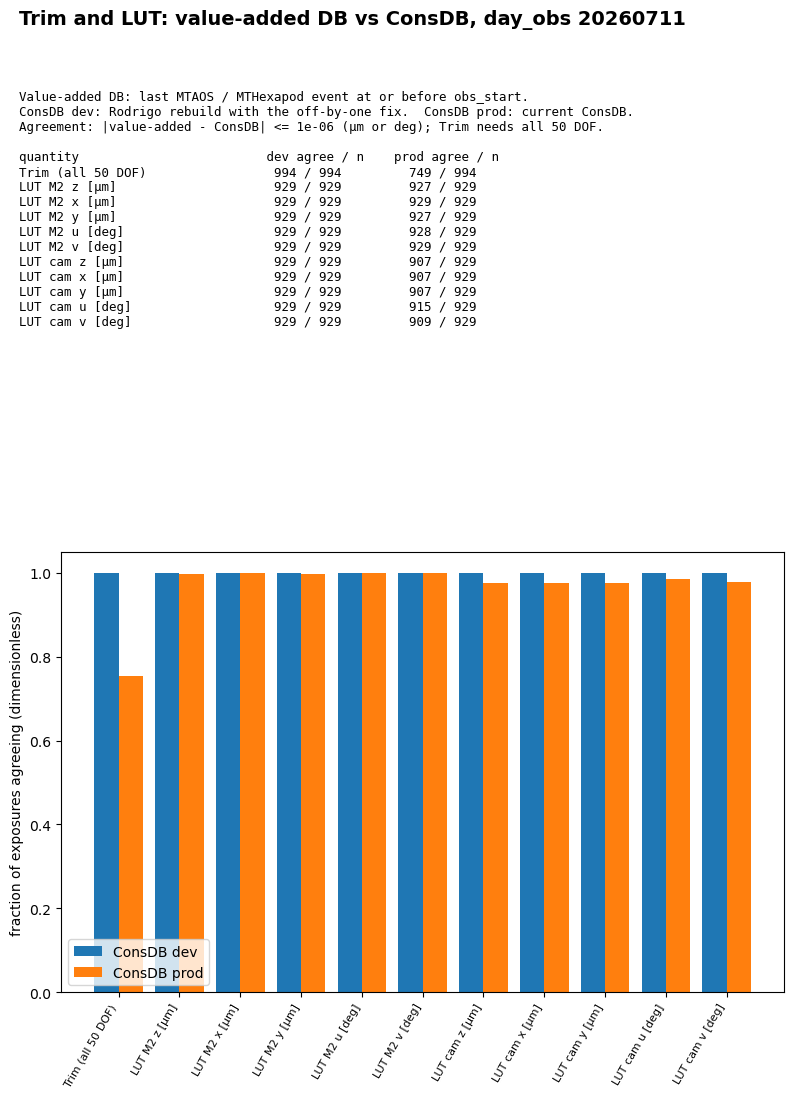

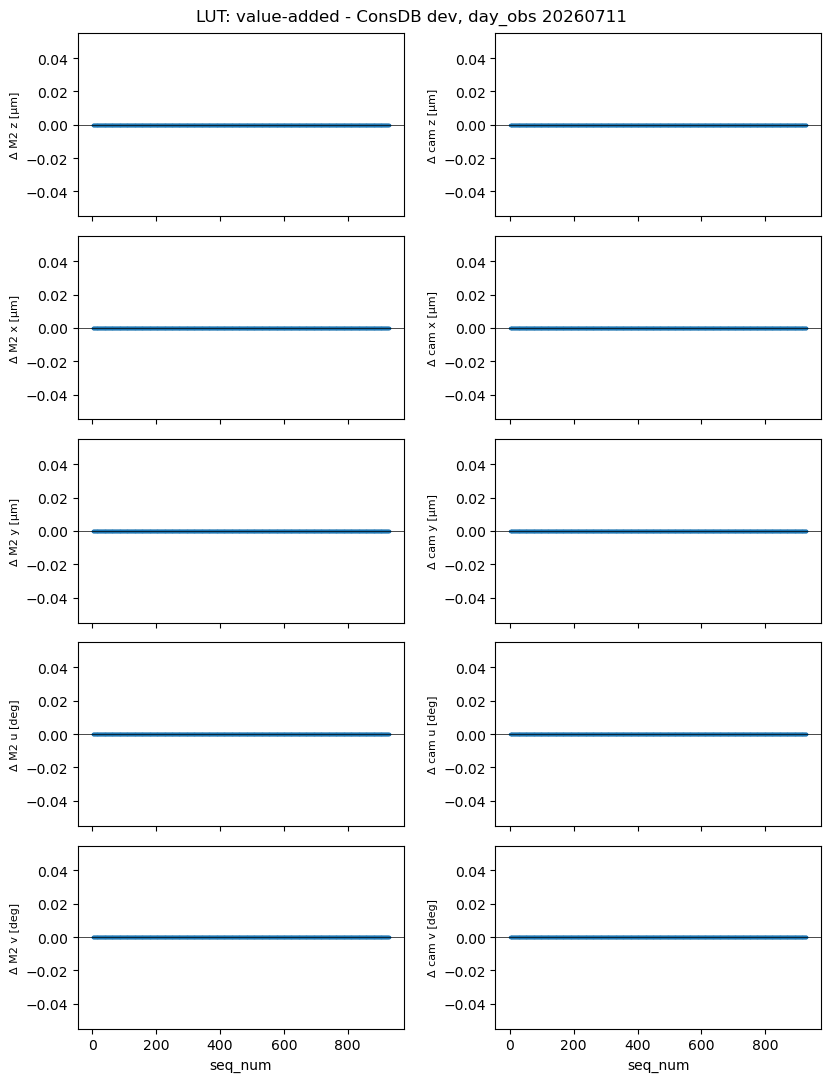

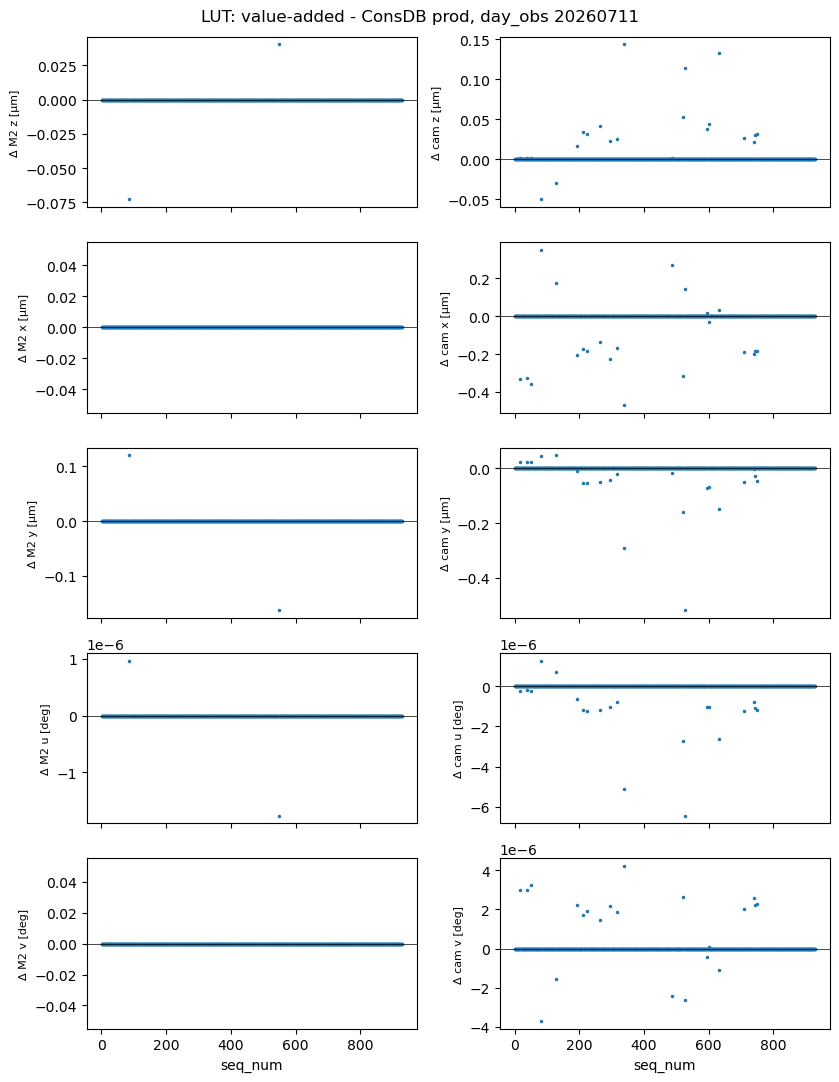

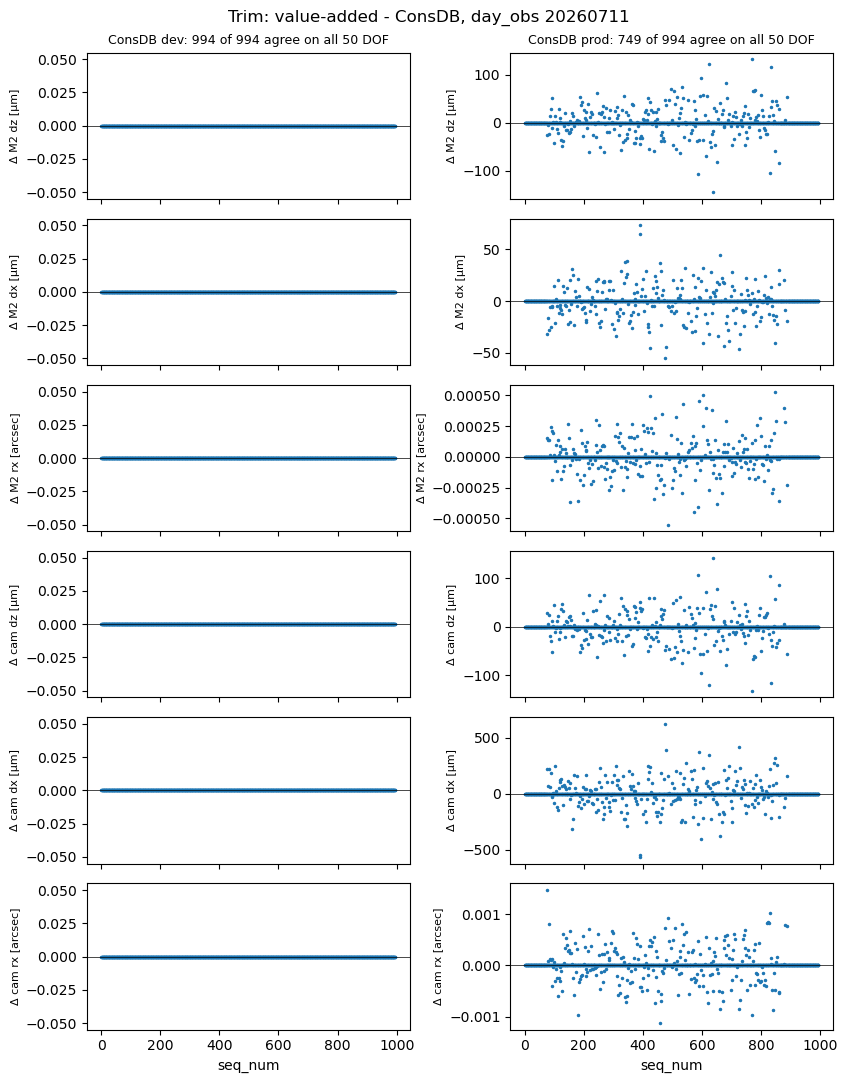

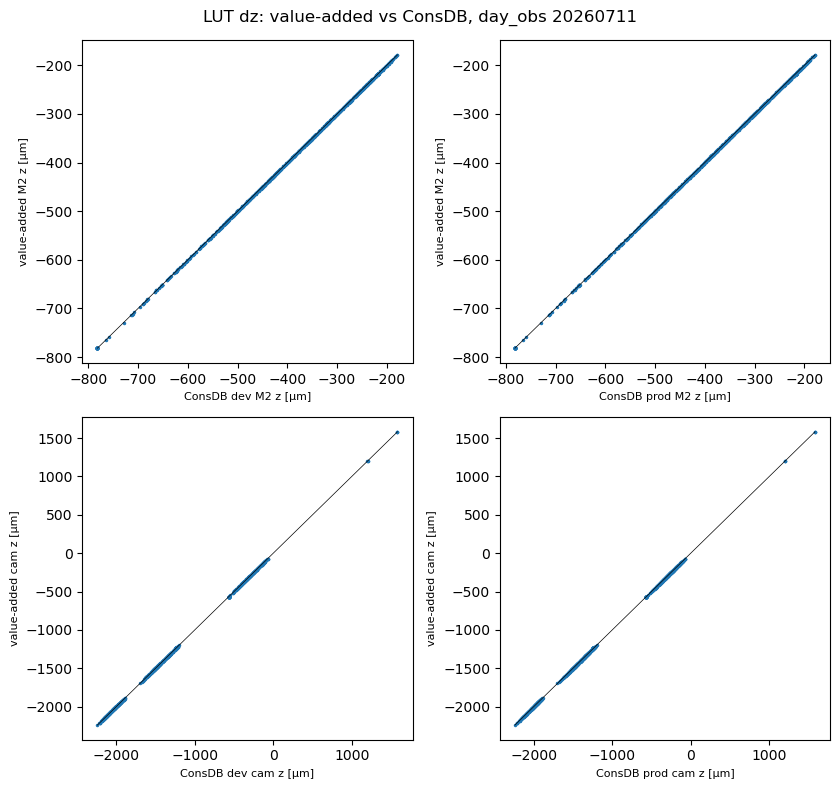

/sdf/group/rubin/u/roodman/LSST/rubin-work/studies/value_added/compare_trim_consdb/20261104_fix_check_20260711/trim_lut_fix_check.pdf


In [6]:
pdf = PdfPages(PDF_PATH)

# Page 1: summary
fig = plt.figure(figsize=(8.5, 11))
fig.text(0.05, 0.96, f'Trim and LUT: value-added DB vs ConsDB, day_obs {DAY_OBS}', fontsize=14, weight='bold')
txt = ['Value-added DB: last MTAOS / MTHexapod event at or before obs_start.',
       'ConsDB dev: Rodrigo rebuild with the off-by-one fix.  ConsDB prod: current ConsDB.',
       f'Agreement: |value-added - ConsDB| <= {ATOL:g} (µm or deg); Trim needs all 50 DOF.', '',
       f"{'quantity':28s}  {'dev agree / n':>16s}  {'prod agree / n':>16s}"]
for q in summary.quantity.unique():
    s = summary[summary.quantity == q].set_index('version')
    txt.append(f"{q:28s}  {s.n_agree['dev']:>7d} / {s.n['dev']:<6d}  {s.n_agree['prod']:>7d} / {s.n['prod']:<6d}")
fig.text(0.05, 0.9, '\n'.join(txt), family='monospace', fontsize=9, va='top')
ax = fig.add_axes([0.1, 0.08, 0.85, 0.4])
qs = summary.quantity.unique()
x = np.arange(len(qs))
for i, v in enumerate(VERSIONS):
    f = summary[summary.version == v].set_index('quantity').loc[qs, 'frac_agree']
    ax.bar(x + (i - 0.5) * 0.4, f, 0.4, label=f'ConsDB {v}')
ax.set_xticks(x, qs, rotation=60, ha='right', fontsize=8)
ax.set_ylabel('fraction of exposures agreeing (dimensionless)')
ax.set_ylim(0, 1.05); ax.legend(loc='lower left')
pdf.savefig(fig); plt.show()

# Page 2: LUT difference vs seq_num, per axis
for v in VERSIONS:
    jl = diffs[(v, 'lut')]
    fig, axs = plt.subplots(5, 2, figsize=(8.5, 11), sharex=True)
    for i, k in enumerate(LUT_MAP):
        ax = axs[i % 5, i // 5]
        d = jl[k].astype(float) - jl[k + '_c'].astype(float)
        ax.plot(jl.seq_num, d, '.', ms=3)
        ax.set_ylabel(f'Δ {LUT_LABEL[k]}', fontsize=8)
        ax.axhline(0, color='k', lw=0.5)
    for ax in axs[-1]: ax.set_xlabel('seq_num')
    fig.suptitle(f'LUT: value-added - ConsDB {v}, day_obs {DAY_OBS}')
    fig.tight_layout(); pdf.savefig(fig); plt.show()

# Page 3: Trim, hexapod DOF difference vs seq_num
TRIM_SHOW = {'dof0': 'M2 dz [µm]', 'dof1': 'M2 dx [µm]', 'dof3': 'M2 rx [arcsec]',
             'dof5': 'cam dz [µm]', 'dof6': 'cam dx [µm]', 'dof8': 'cam rx [arcsec]'}
fig, axs = plt.subplots(len(TRIM_SHOW), 2, figsize=(8.5, 11), sharex=True)
for j, v in enumerate(VERSIONS):
    jt, ok = diffs[(v, 'trim')]
    for i, (k, lab) in enumerate(TRIM_SHOW.items()):
        ax = axs[i, j]
        ax.plot(jt.seq_num, jt[k].astype(float) - jt[k + '_c'].astype(float), '.', ms=3)
        ax.axhline(0, color='k', lw=0.5); ax.set_ylabel(f'Δ {lab}', fontsize=8)
    axs[0, j].set_title(f'ConsDB {v}: {int(ok.all(1).sum())} of {len(jt)} agree on all 50 DOF', fontsize=9)
    axs[-1, j].set_xlabel('seq_num')
fig.suptitle(f'Trim: value-added - ConsDB, day_obs {DAY_OBS}')
fig.tight_layout(); pdf.savefig(fig); plt.show()

# Page 4: LUT value vs value for camera z and M2 z
fig, axs = plt.subplots(2, 2, figsize=(8.5, 8))
for j, v in enumerate(VERSIONS):
    jl = diffs[(v, 'lut')]
    for i, k in enumerate(('lut_dof0', 'lut_dof5')):
        ax = axs[i, j]
        ax.plot(jl[k + '_c'], jl[k], '.', ms=3)
        lim = [np.nanmin(jl[k]), np.nanmax(jl[k])]
        ax.plot(lim, lim, 'k-', lw=0.5)
        ax.set_xlabel(f'ConsDB {v} {LUT_LABEL[k]}', fontsize=8); ax.set_ylabel(f'value-added {LUT_LABEL[k]}', fontsize=8)
fig.suptitle(f'LUT dz: value-added vs ConsDB, day_obs {DAY_OBS}')
fig.tight_layout(); pdf.savefig(fig); plt.show()
pdf.close()
print(PDF_PATH)